<a href="https://colab.research.google.com/github/faat-prasojo/Pembelajaran_Mesin_2026/blob/main/Pertemuan%2009/Tugas_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Klasifikasi Suara Male vs Female dengan kNN (voice.csv)

Isi notebook:
1. Load data & EDA singkat
2. Setup evaluasi (split, scaling, CV)
3. Eksperimen seleksi fitur (soal 2)
4. Penentuan nilai *k* terbaik + grafik analisis (soal 3)
5. Evaluasi akhir di test set

**Cara pakai di Google Colab:** Runtime > Run all, lalu upload `voice.csv` saat diminta di sel pertama.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RepeatedStratifiedKFold, cross_val_score)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay)

# Upload voice.csv jika belum ada (khusus Google Colab)
if not os.path.exists("voice.csv"):
    from google.colab import files
    files.upload()

df = pd.read_csv("voice.csv")
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplikat baris:", df.duplicated().sum())
print(df["label"].value_counts())
df.head()

Shape: (3168, 21)
Missing values: 0
Duplikat baris: 2
label
male      1584
female    1584
Name: count, dtype: int64


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


## 1. EDA singkat

Yang perlu dicek sebelum kNN: skala fitur (kNN berbasis jarak, jadi fitur berskala besar akan mendominasi) dan korelasi antar fitur (fitur redundan memberi bobot ganda pada jarak).

              min          max      rentang
kurt     2.068455  1309.612887  1307.544432
skew     0.141735    34.725453    34.583718
maxdom   0.007812    21.867188    21.859375
dfrange  0.000000    21.843750    21.843750
meandom  0.007812     2.957682     2.949870
modindx  0.000000     0.932374     0.932374

meanfreq == centroid di semua baris: True
dfrange vs maxdom, korelasi: 0.9998


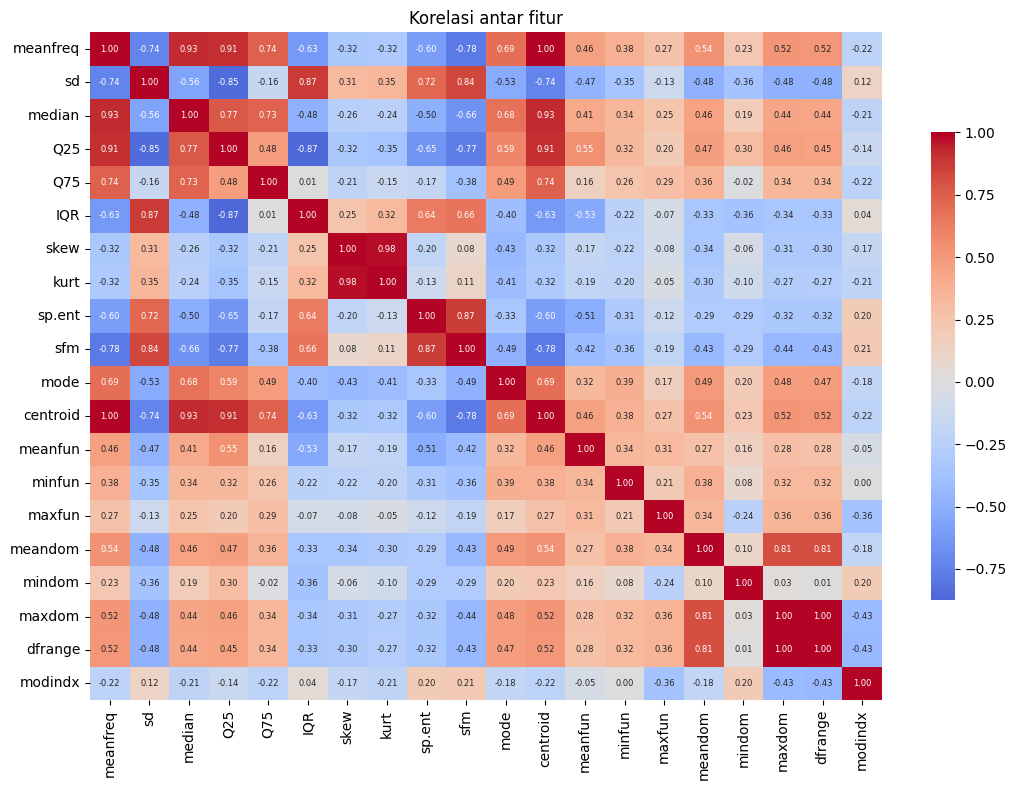

In [ ]:
X = df.drop(columns="label")
y = (df["label"] == "male").astype(int)   # male=1, female=0

# Rentang nilai tiap fitur -> menunjukkan kenapa scaling wajib
rng = X.describe().loc[["min", "max"]].T
rng["rentang"] = rng["max"] - rng["min"]
print(rng.sort_values("rentang", ascending=False).head(6))

# Apakah meanfreq dan centroid identik?
print("\nmeanfreq == centroid di semua baris:", np.allclose(X["meanfreq"], X["centroid"]))
print("dfrange vs maxdom, korelasi:", round(X["dfrange"].corr(X["maxdom"]), 4))

plt.figure(figsize=(11, 8))
sns.heatmap(X.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 6}, cbar_kws={"shrink": .7})
plt.title("Korelasi antar fitur")
plt.tight_layout(); plt.show()

## 2. Setup evaluasi

- **Split 80/20 stratified** (`random_state=42`). Test set (634 sampel) **tidak disentuh** selama seleksi fitur dan pemilihan *k*.
- **StandardScaler di dalam `Pipeline`** supaya scaler hanya di-fit pada data training tiap fold CV (mencegah data leakage).
- Seleksi fitur dan pemilihan *k* memakai **cross-validation pada data training saja**.

In [ ]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", Xtr.shape, "| Test:", Xte.shape)

cv5  = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rcv  = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=1)  # lebih stabil

def knn_pipe(k=5):
    return make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))

def cv_acc(cols, k=5, cv=cv5):
    return cross_val_score(knn_pipe(k), Xtr[cols], ytr, cv=cv, scoring="accuracy").mean()

# Baseline: semua 20 fitur, k=5
all_feats = list(X.columns)
print(f"Baseline 20 fitur (k=5): CV acc = {cv_acc(all_feats):.4f}")

# Pembanding: tanpa scaling -> membuktikan scaling diperlukan
raw = cross_val_score(KNeighborsClassifier(5), Xtr, ytr, cv=cv5).mean()
print(f"Tanpa scaling (k=5):     CV acc = {raw:.4f}")

Train: (2534, 20) | Test: (634, 20)
Baseline 20 fitur (k=5): CV acc = 0.9696
Tanpa scaling (k=5):     CV acc = 0.7021


## 3. Eksperimen seleksi fitur (Soal 2)

Empat pendekatan dibandingkan, k dikunci di 5 selama tahap ini:

| Pendekatan | Jenis | Cara kerja |
|---|---|---|
| ANOVA F-score | Filter | ranking fitur dari uji F terhadap label |
| Mutual Information | Filter | ranking dari ketergantungan non-linear |
| Random Forest importance | Embedded | ranking dari kontribusi pada split pohon |
| Forward Selection (kNN) | Wrapper | tambah fitur satu per satu yang paling menaikkan CV accuracy kNN |

Untuk tiga ranking pertama, diuji top-1 sampai top-20 fitur.

In [ ]:
F, _ = f_classif(Xtr, ytr)
rank_F  = pd.Series(F, index=all_feats).sort_values(ascending=False)
rank_MI = pd.Series(mutual_info_classif(Xtr, ytr, random_state=42), index=all_feats).sort_values(ascending=False)
rf = RandomForestClassifier(n_estimators=300, random_state=42).fit(Xtr, ytr)
rank_RF = pd.Series(rf.feature_importances_, index=all_feats).sort_values(ascending=False)

pd.DataFrame({"F-score": rank_F.index, "MI": rank_MI.index, "RF": rank_RF.index}).head(10)

,F-score,MI,RF
0,meanfun,meanfun,meanfun
1,IQR,IQR,IQR
2,Q25,Q25,Q25
3,sp.ent,sd,sd
4,sd,mode,sp.ent
5,sfm,sp.ent,sfm
6,centroid,sfm,centroid
7,meanfreq,meanfreq,meanfreq
8,median,centroid,mode
9,mindom,mindom,median


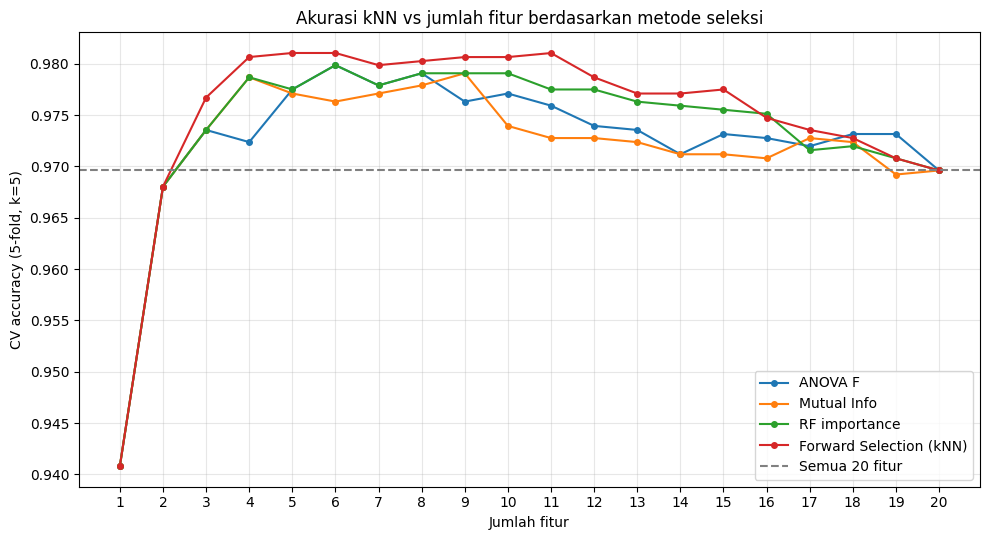

ANOVA F                   puncak di  6 fitur -> 0.9799
Mutual Info               puncak di  9 fitur -> 0.9791
RF importance             puncak di  6 fitur -> 0.9799
Forward Selection (kNN)   puncak di  5 fitur -> 0.9811

Urutan Forward Selection: ['meanfun', 'IQR', 'sfm', 'mode', 'skew', 'kurt', 'minfun', 'sp.ent', 'maxdom', 'sd', 'median', 'maxfun', 'Q25', 'meanfreq', 'centroid', 'Q75', 'dfrange', 'modindx', 'meandom', 'mindom']


In [ ]:
curves = {}
for name, rank in [("ANOVA F", rank_F), ("Mutual Info", rank_MI), ("RF importance", rank_RF)]:
    curves[name] = [cv_acc(list(rank.index[:n])) for n in range(1, 21)]

# Forward selection (wrapper) manual, supaya jalur skornya bisa diplot
selected, remaining, path = [], list(all_feats), []
while remaining:
    scores = {f: cv_acc(selected + [f]) for f in remaining}
    best_f = max(scores, key=scores.get)
    selected.append(best_f); remaining.remove(best_f)
    path.append(scores[best_f])
curves["Forward Selection (kNN)"] = path
fs_order = selected.copy()

plt.figure(figsize=(10, 5.5))
for name, vals in curves.items():
    plt.plot(range(1, 21), vals, marker="o", ms=4, label=name)
plt.axhline(cv_acc(all_feats), color="gray", ls="--", label="Semua 20 fitur")
plt.xlabel("Jumlah fitur"); plt.ylabel("CV accuracy (5-fold, k=5)")
plt.title("Akurasi kNN vs jumlah fitur berdasarkan metode seleksi")
plt.xticks(range(1, 21)); plt.grid(alpha=.3); plt.legend(); plt.tight_layout(); plt.show()

for name, vals in curves.items():
    n = int(np.argmax(vals)) + 1
    print(f"{name:25s} puncak di {n:2d} fitur -> {max(vals):.4f}")
print("\nUrutan Forward Selection:", fs_order)

### Membandingkan kandidat fitur secara adil

Selisih antar metode di atas sangat kecil (di bawah 0.4 poin persen), jadi perlu CV yang lebih stabil (5-fold x 5 pengulangan) untuk melihat apakah selisihnya nyata. Test set hanya dipakai sebagai pengecekan akhir, bukan untuk memilih.

In [ ]:
best_n = {k: int(np.argmax(v)) + 1 for k, v in curves.items()}
candidates = {
    "Semua fitur (20)":            all_feats,
    "ANOVA F top-6":               list(rank_F.index[:6]),
    "Mutual Info top-9":           list(rank_MI.index[:9]),
    "RF importance top-6":         list(rank_RF.index[:6]),
    f"Forward Sel. ({best_n['Forward Selection (kNN)']} fitur)": fs_order[:best_n['Forward Selection (kNN)']],
    "Forward Sel. (3 fitur)":      fs_order[:3],
}

rows = []
for name, cols in candidates.items():
    s = cross_val_score(knn_pipe(5), Xtr[cols], ytr, cv=rcv)
    m = knn_pipe(5).fit(Xtr[cols], ytr)
    rows.append({"Kandidat": name, "n": len(cols),
                 "CV mean": s.mean(), "CV std": s.std(),
                 "Test acc": accuracy_score(yte, m.predict(Xte[cols])),
                 "Fitur": ", ".join(cols)})
res = pd.DataFrame(rows).sort_values("CV mean", ascending=False).reset_index(drop=True)
pd.set_option("display.max_colwidth", 90)
res.round(4)

,Kandidat,n,CV mean,CV std,Test acc,Fitur
0,Forward Sel. (5 fitur),5,0.9802,0.0065,0.9874,"meanfun, IQR, sfm, mode, skew"
1,ANOVA F top-6,6,0.9795,0.0057,0.9858,"meanfun, IQR, Q25, sp.ent, sd, sfm"
2,RF importance top-6,6,0.9795,0.0057,0.9858,"meanfun, IQR, Q25, sd, sp.ent, sfm"
3,Mutual Info top-9,9,0.9764,0.0077,0.9795,"meanfun, IQR, Q25, sd, mode, sp.ent, sfm, meanfreq, centroid"
4,Forward Sel. (3 fitur),3,0.9759,0.0063,0.9874,"meanfun, IQR, sfm"
5,Semua fitur (20),20,0.9690,0.0092,0.9763,"meanfreq, sd, median, Q25, Q75, IQR, skew, kurt, sp.ent, sfm, mode, centroid, meanfun,..."


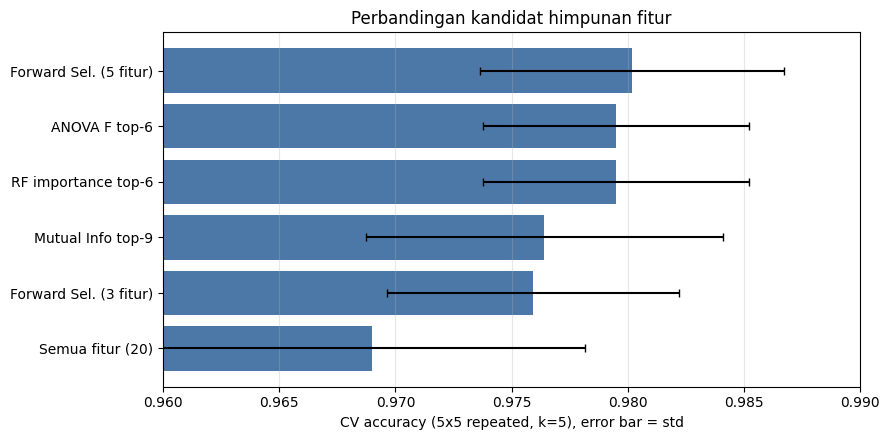

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
order = res.iloc[::-1]
ax.barh(order["Kandidat"], order["CV mean"], xerr=order["CV std"], color="#4C78A8", capsize=3)
ax.set_xlim(0.96, 0.99); ax.set_xlabel("CV accuracy (5x5 repeated, k=5), error bar = std")
ax.set_title("Perbandingan kandidat himpunan fitur"); ax.grid(axis="x", alpha=.3)
plt.tight_layout(); plt.show()

### Fitur terpilih

Dipilih himpunan hasil **Forward Selection dengan kNN** (CV tertinggi, dan paling sedikit fitur di antara kandidat yang setara). Kode di bawah mengambilnya langsung dari hasil eksperimen.

In [ ]:
n_fs = best_n["Forward Selection (kNN)"]
FINAL_FEATS = fs_order[:n_fs]
print("Fitur terpilih:", FINAL_FEATS)

# Seberapa penting tiap fitur terpilih? -> drop-one analysis
base = cross_val_score(knn_pipe(5), Xtr[FINAL_FEATS], ytr, cv=rcv).mean()
drop = {f: base - cross_val_score(knn_pipe(5), Xtr[[c for c in FINAL_FEATS if c != f]], ytr, cv=rcv).mean()
        for f in FINAL_FEATS}
pd.Series(drop, name="Penurunan akurasi jika fitur dibuang").sort_values(ascending=False).round(4)

Fitur terpilih: ['meanfun', 'IQR', 'sfm', 'mode', 'skew']


meanfun    0.0388
IQR        0.0140
sfm        0.0054
mode       0.0044
skew       0.0009
Name: Penurunan akurasi jika fitur dibuang, dtype: float64

## 4. Nilai k terbaik (Soal 3)

*k* diuji dari 1 sampai 30 pada fitur terpilih memakai repeated CV pada data training. Kurva training accuracy ikut diplot untuk melihat zona overfitting (k kecil) dan underfitting (k besar).

In [ ]:
ks = range(1, 31)
cv_mean, cv_std, tr_acc = [], [], []
for k in ks:
    s = cross_val_score(knn_pipe(k), Xtr[FINAL_FEATS], ytr, cv=rcv)
    cv_mean.append(s.mean()); cv_std.append(s.std())
    tr_acc.append(knn_pipe(k).fit(Xtr[FINAL_FEATS], ytr).score(Xtr[FINAL_FEATS], ytr))
cv_mean, cv_std, tr_acc = map(np.array, (cv_mean, cv_std, tr_acc))
ks = np.array(list(ks))

best_i = int(cv_mean.argmax())
se = cv_std[best_i] / np.sqrt(rcv.get_n_splits())          # standard error
thr = cv_mean[best_i] - se
# aturan 1-SE: ambil k terbesar (model paling sederhana) yang masih dalam 1 SE dari puncak, dan ganjil
cands = [k for k, m in zip(ks, cv_mean) if m >= thr and k % 2 == 1]
K_FINAL = max(cands)

print(f"CV tertinggi: k={ks[best_i]} -> {cv_mean[best_i]:.4f} (SE={se:.4f})")
print(f"Batas 1-SE: {thr:.4f}; k ganjil yang lolos: {cands}")
print(f"k dipilih: {K_FINAL} -> CV {cv_mean[K_FINAL-1]:.4f}")

CV tertinggi: k=4 -> 0.9810 (SE=0.0012)
Batas 1-SE: 0.9797; k ganjil yang lolos: [np.int64(3), np.int64(5)]
k dipilih: 5 -> CV 0.9802


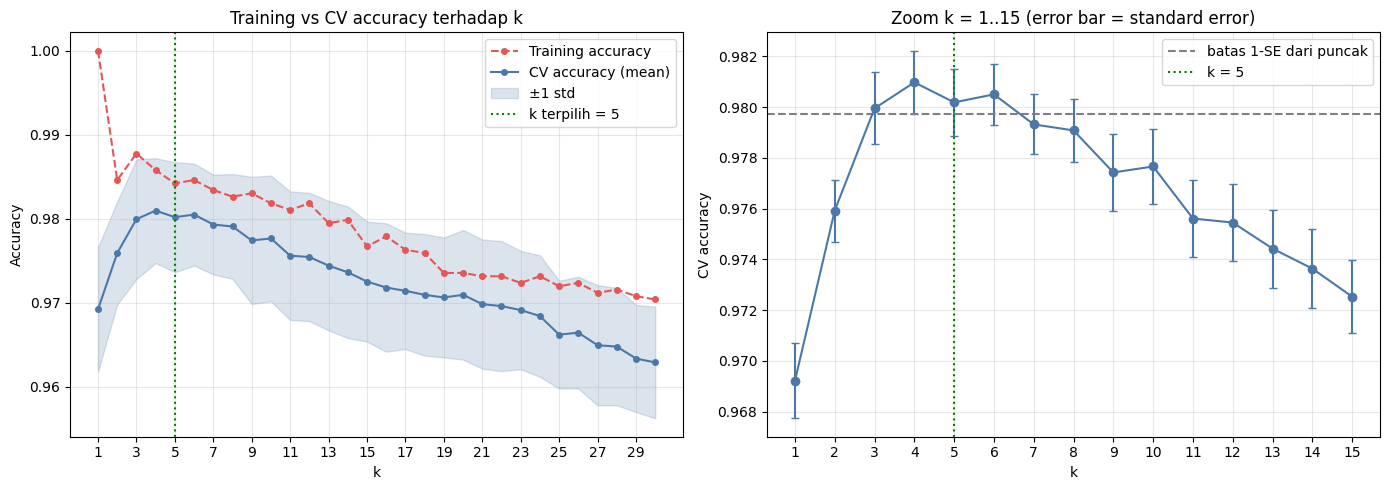

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# (a) kurva CV vs train
ax[0].plot(ks, tr_acc, "o--", ms=4, label="Training accuracy", color="#E45756")
ax[0].plot(ks, cv_mean, "o-", ms=4, label="CV accuracy (mean)", color="#4C78A8")
ax[0].fill_between(ks, cv_mean - cv_std, cv_mean + cv_std, alpha=.2, color="#4C78A8", label="±1 std")
ax[0].axvline(K_FINAL, color="green", ls=":", label=f"k terpilih = {K_FINAL}")
ax[0].set_xlabel("k"); ax[0].set_ylabel("Accuracy"); ax[0].set_xticks(range(1, 31, 2))
ax[0].set_title("Training vs CV accuracy terhadap k"); ax[0].grid(alpha=.3); ax[0].legend()

# (b) zoom ke area puncak
z = ks <= 15
ax[1].errorbar(ks[z], cv_mean[z], yerr=cv_std[z] / np.sqrt(rcv.get_n_splits()), fmt="o-", capsize=3, color="#4C78A8")
ax[1].axhline(thr, color="gray", ls="--", label="batas 1-SE dari puncak")
ax[1].axvline(K_FINAL, color="green", ls=":", label=f"k = {K_FINAL}")
ax[1].set_xlabel("k"); ax[1].set_ylabel("CV accuracy"); ax[1].set_xticks(range(1, 16))
ax[1].set_title("Zoom k = 1..15 (error bar = standard error)"); ax[1].grid(alpha=.3); ax[1].legend()
plt.tight_layout(); plt.show()

### Alasan pemilihan k

1. **k kecil (1 sampai 2):** training accuracy mendekati 1.0 tetapi CV accuracy lebih rendah. Model menghafal noise (overfitting).
2. **k besar (di atas ±10):** CV accuracy turun terus karena batas keputusan terlalu halus dan tetangga dari kelas lain ikut menentukan (underfitting).
3. **Zona k = 3 sampai 6 membentuk plateau**: semua k di zona ini berada dalam 1 standard error dari puncak (k=4), jadi tidak bisa dibedakan secara statistik.
4. Karena itu dipakai **aturan 1-SE** plus syarat **k ganjil** (menghindari voting seri pada 2 kelas), menghasilkan k yang dicetak di output di atas.

## 5. Evaluasi akhir pada test set

Pertama kali test set dipakai untuk menilai konfigurasi final: fitur terpilih + k terpilih.

Fitur : ['meanfun', 'IQR', 'sfm', 'mode', 'skew']
k     : 5
Test accuracy: 0.9874  (626/634 benar)

              precision    recall  f1-score   support

      female     0.9905    0.9842    0.9873       317
        male     0.9843    0.9905    0.9874       317

    accuracy                         0.9874       634
   macro avg     0.9874    0.9874    0.9874       634
weighted avg     0.9874    0.9874    0.9874       634



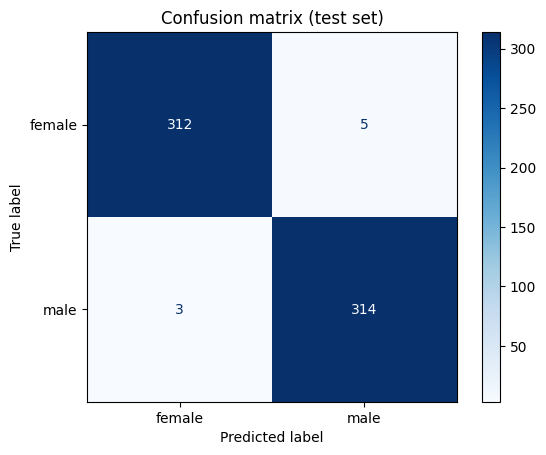

Pembanding 20 fitur, k=5 -> test acc: 0.9763


In [ ]:
final = knn_pipe(K_FINAL).fit(Xtr[FINAL_FEATS], ytr)
pred = final.predict(Xte[FINAL_FEATS])
print(f"Fitur : {FINAL_FEATS}")
print(f"k     : {K_FINAL}")
print(f"Test accuracy: {accuracy_score(yte, pred):.4f}  ({(pred == yte).sum()}/{len(yte)} benar)\n")
print(classification_report(yte, pred, target_names=["female", "male"], digits=4))

ConfusionMatrixDisplay.from_predictions(yte, pred, display_labels=["female", "male"], cmap="Blues")
plt.title("Confusion matrix (test set)"); plt.show()

# Pembanding: konfigurasi awal (20 fitur, k=5)
base_m = knn_pipe(5).fit(Xtr, ytr)
print(f"Pembanding 20 fitur, k=5 -> test acc: {base_m.score(Xte, yte):.4f}")